In [88]:
#Data manipulation
import pandas as pd
import numpy as np

# Plotting
import matplotlib.pyplot as plt

# Preprocessing
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import (
train_test_split,
RandomizedSearchCV,
TimeSeriesSplit,
cross_val_score
)

# K-mean clustering
from sklearn.cluster import KMeans

# Classifier
from sklearn.ensemble import RandomForestClassifier

# Metrics
from sklearn.metrics import (precision_recall_curve,
roc_curve,
RocCurveDisplay,
ConfusionMatrixDisplay
)

from sklearn.metrics import (accuracy_score,
f1_score,
recall_score,
precision_score,
roc_auc_score,
auc
)

from sklearn.metrics import (classification_report,
confusion_matrix
)

# Import tensorflow and keras
import tensorflow
import keras 

# Import pandas-ta
import pandas_ta as ta

In [89]:
files = ["CMA.csv", "HML.csv", "MKT.csv", "RMW.csv", "SMB.csv", "UMD.csv"]
tickers = ["cma", "hml", "mkt", "rmw", "smb", "umd",]

data = pd.DataFrame()

# Load files, extract the 'Close' column, and concatenate DataFrames
for i, file in enumerate(files):
    df = pd.read_csv(file, index_col=0, parse_dates=True, usecols=['date', 'close'])
    df.columns = [f"Close_{tickers[i]}"]  # Rename 'Close' column with ticker suffix
    data = pd.concat([data, df], axis=1)

# Also save each original ticker data into a single dataframe for later calculation of technical indicators
for ticker in tickers:
    globals()[ticker] = pd.read_csv(ticker + ".csv", index_col=0, parse_dates=True)

# Save the concatenated DataFrame to a new CSV file
data.to_csv("concatenated_closes.csv")

data


,Close_cma,Close_hml,Close_mkt,Close_rmw,Close_smb,Close_umd
date,,,,,,
2/1/2014,100.557344,101.654116,94.677887,100.240243,101.235292,98.681401
3/1/2014,100.452750,103.314478,94.177525,99.544800,100.475639,98.564815
6/1/2014,100.386385,102.445666,94.693658,98.665899,98.574632,99.743182
7/1/2014,99.739388,100.809123,97.162546,99.425262,98.126280,100.336994
8/1/2014,100.057959,100.218158,96.824794,99.817369,97.780785,100.198034
...,...,...,...,...,...,...
24/4/2024,163.279450,137.004451,127.042559,105.443845,116.124809,191.263376
25/4/2024,162.954590,136.450907,127.374724,105.673171,116.582596,191.810751
26/4/2024,161.715370,137.514225,126.979863,106.109936,116.859371,191.888061


## Exploratory Data Analysis

In [90]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
Close_cma,2507.0,121.447539,16.351098,99.142622,107.595953,117.245210,129.907561,166.667970
Close_hml,2507.0,130.463038,17.471080,99.472920,119.446821,131.180002,140.382946,170.913791
Close_mkt,2507.0,131.681843,14.473155,89.455829,120.994125,132.149616,143.955931,155.459147
Close_rmw,2507.0,104.424673,7.689591,84.335946,99.687239,103.522896,108.547883,133.273850
Close_smb,2507.0,108.093572,14.970156,73.234252,95.702319,114.557540,119.913614,130.826035
Close_umd,2507.0,133.747526,23.839062,94.153230,110.983528,138.850625,146.072182,197.827201


In [91]:
# check for missing values
data.isnull().sum()

Close_cma    0
Close_hml    0
Close_mkt    0
Close_rmw    0
Close_smb    0
Close_umd    0
dtype: int64

In [92]:
files = ["CMA.csv", "HML.csv", "MKT.csv", "RMW.csv", "SMB.csv", "UMD.csv"]
tickers = ["cma", "hml", "mkt", "rmw", "smb", "umd"]

ret = pd.DataFrame()

# Load files, extract the 'RET' column, and concatenate DataFrames
for i, file in enumerate(files):
    df = pd.read_csv(file, index_col=0, parse_dates=True, usecols=['date', 'return'])
    df.columns = [f"RET_{tickers[i]}"]  # Rename 'RET' column with ticker suffix
    ret = pd.concat([ret, df], axis=1)

# Save the concatenated DataFrame to a new CSV file if needed
ret.to_csv("concatenated_returns.csv")

ret

,RET_cma,RET_hml,RET_mkt,RET_rmw,RET_smb,RET_umd
date,,,,,,
2/1/2014,0.005573,0.016541,-0.053221,0.002402,0.012353,-0.013186
3/1/2014,-0.001040,0.016333,-0.005285,-0.006938,-0.007504,-0.001181
6/1/2014,-0.000661,-0.008409,0.005480,-0.008829,-0.018920,0.011955
7/1/2014,-0.006445,-0.015975,0.026072,0.007696,-0.004548,0.005953
8/1/2014,0.003194,-0.005862,-0.003476,0.003944,-0.003521,-0.001385
...,...,...,...,...,...,...
24/4/2024,-0.006187,-0.010302,0.003068,0.003958,-0.005578,0.005125
25/4/2024,-0.001990,-0.004040,0.002615,0.002175,0.003942,0.002862
26/4/2024,-0.007605,0.007793,-0.003100,0.004133,0.002374,0.000403


In [93]:
# Define the SMA periods
sma_periods = [5, 10, 20, 50, 100, 200]

# Loop through each ticker and calculate SMA for each period
for ticker in tickers:
    # Identify the column that contains the close prices (assuming the column name is 'close' followed by the ticker)
    close_col = f"Close_{ticker}"
    
    # Check if the column exists in the data DataFrame
    if close_col in data.columns:
        for period in sma_periods:
            # Calculate SMA
            sma_col = f"SMA_{period}_{ticker}"
            sma_series = ta.sma(data[close_col], length=period)
            
            # Add SMA to the DataFrame with appropriate name
            data[sma_col] = sma_series
    else:
        print(f"Column {close_col} does not exist in the DataFrame.")

print(data)

            Close_cma   Close_hml   Close_mkt   Close_rmw   Close_smb  \
date                                                                    
2/1/2014   100.557344  101.654116   94.677887  100.240243  101.235292   
3/1/2014   100.452750  103.314478   94.177525   99.544800  100.475639   
6/1/2014   100.386385  102.445666   94.693658   98.665899   98.574632   
7/1/2014    99.739388  100.809123   97.162546   99.425262   98.126280   
8/1/2014   100.057959  100.218158   96.824794   99.817369   97.780785   
...               ...         ...         ...         ...         ...   
24/4/2024  163.279450  137.004451  127.042559  105.443845  116.124809   
25/4/2024  162.954590  136.450907  127.374724  105.673171  116.582596   
26/4/2024  161.715370  137.514225  126.979863  106.109936  116.859371   
29/4/2024  163.066388  138.917666  127.191510  105.437125  117.486626   
30/4/2024  163.662501  138.063658  127.798171  105.398411  117.506506   

            Close_umd   SMA_5_cma  SMA_10_cma  SMA

In [94]:
# Define the EMA periods
ema_periods = [5, 8, 10, 12, 25, 26, 50, 200]

# Loop through each ticker and calculate EMA for each period
for ticker in tickers:
    # Identify the column that contains the close prices (assuming the column name is 'close' followed by the ticker)
    close_col = f"Close_{ticker}"
    
    # Check if the column exists in the data DataFrame
    if close_col in data.columns:
        for period in ema_periods:
            # Calculate EMA
            ema_col = f"EMA_{period}_{ticker}"
            ema_series = ta.ema(data[close_col], length=period)
            
            # Add EMA to the DataFrame with appropriate name
            data[ema_col] = ema_series
    else:
        print(f"Column {close_col} does not exist in the DataFrame.")

print(data) 

            Close_cma   Close_hml   Close_mkt   Close_rmw   Close_smb  \
date                                                                    
2/1/2014   100.557344  101.654116   94.677887  100.240243  101.235292   
3/1/2014   100.452750  103.314478   94.177525   99.544800  100.475639   
6/1/2014   100.386385  102.445666   94.693658   98.665899   98.574632   
7/1/2014    99.739388  100.809123   97.162546   99.425262   98.126280   
8/1/2014   100.057959  100.218158   96.824794   99.817369   97.780785   
...               ...         ...         ...         ...         ...   
24/4/2024  163.279450  137.004451  127.042559  105.443845  116.124809   
25/4/2024  162.954590  136.450907  127.374724  105.673171  116.582596   
26/4/2024  161.715370  137.514225  126.979863  106.109936  116.859371   
29/4/2024  163.066388  138.917666  127.191510  105.437125  117.486626   
30/4/2024  163.662501  138.063658  127.798171  105.398411  117.506506   

            Close_umd   SMA_5_cma  SMA_10_cma  SMA

In [95]:
# Define the RSI periods
rsi_periods = [5, 9, 14, 30]

# Loop through each ticker and calculate RSI for each period
for ticker in tickers:
    # Identify the column that contains the close prices (assuming the column name is 'close' followed by the ticker)
    close_col = f"Close_{ticker}"
    
    # Check if the column exists in the data DataFrame
    if close_col in data.columns:
        for period in rsi_periods:
            # Calculate RSI
            rsi_col = f"RSI_{period}_{ticker}"
            rsi_series = ta.rsi(data[close_col], length=period)
            
            # Add RSI to the DataFrame with appropriate name
            data[rsi_col] = rsi_series
    else:
        print(f"Column {close_col} does not exist in the DataFrame.")

print(data)

            Close_cma   Close_hml   Close_mkt   Close_rmw   Close_smb  \
date                                                                    
2/1/2014   100.557344  101.654116   94.677887  100.240243  101.235292   
3/1/2014   100.452750  103.314478   94.177525   99.544800  100.475639   
6/1/2014   100.386385  102.445666   94.693658   98.665899   98.574632   
7/1/2014    99.739388  100.809123   97.162546   99.425262   98.126280   
8/1/2014   100.057959  100.218158   96.824794   99.817369   97.780785   
...               ...         ...         ...         ...         ...   
24/4/2024  163.279450  137.004451  127.042559  105.443845  116.124809   
25/4/2024  162.954590  136.450907  127.374724  105.673171  116.582596   
26/4/2024  161.715370  137.514225  126.979863  106.109936  116.859371   
29/4/2024  163.066388  138.917666  127.191510  105.437125  117.486626   
30/4/2024  163.662501  138.063658  127.798171  105.398411  117.506506   

            Close_umd   SMA_5_cma  SMA_10_cma  SMA

In [96]:
# Define the Bollinger Bands parameters
bb_params = [
    (10, 1.5),
    (20, 2),
    (50, 2.5)
]

# Loop through each ticker and calculate Bollinger Bands for each parameter set
for ticker in tickers:
    # Identify the column that contains the close prices (assuming the column name is 'close' followed by the ticker)
    close_col = f"Close_{ticker}"
    
    # Check if the column exists in the data DataFrame
    if close_col in data.columns:
        for period, std_dev in bb_params:
            # Calculate Bollinger Bands
            bb = ta.bbands(data[close_col], length=period, std=std_dev)
            
            # Extract the Bollinger Bands components from the returned DataFrame
            bb_upper_col = bb.columns[0]
            bb_middle_col = bb.columns[1]
            bb_lower_col = bb.columns[2]
            
            bb_upper = bb[bb_upper_col]
            bb_middle = bb[bb_middle_col]
            bb_lower = bb[bb_lower_col]
            
            # Add Bollinger Bands components to the DataFrame with appropriate names
            data[f"BB_upper_{period}_{std_dev}_{ticker}"] = bb_upper
            data[f"BB_middle_{period}_{std_dev}_{ticker}"] = bb_middle
            data[f"BB_lower_{period}_{std_dev}_{ticker}"] = bb_lower
    else:
        print(f"Column {close_col} does not exist in the DataFrame.")

print(data)

            Close_cma   Close_hml   Close_mkt   Close_rmw   Close_smb  \
date                                                                    
2/1/2014   100.557344  101.654116   94.677887  100.240243  101.235292   
3/1/2014   100.452750  103.314478   94.177525   99.544800  100.475639   
6/1/2014   100.386385  102.445666   94.693658   98.665899   98.574632   
7/1/2014    99.739388  100.809123   97.162546   99.425262   98.126280   
8/1/2014   100.057959  100.218158   96.824794   99.817369   97.780785   
...               ...         ...         ...         ...         ...   
24/4/2024  163.279450  137.004451  127.042559  105.443845  116.124809   
25/4/2024  162.954590  136.450907  127.374724  105.673171  116.582596   
26/4/2024  161.715370  137.514225  126.979863  106.109936  116.859371   
29/4/2024  163.066388  138.917666  127.191510  105.437125  117.486626   
30/4/2024  163.662501  138.063658  127.798171  105.398411  117.506506   

            Close_umd   SMA_5_cma  SMA_10_cma  SMA

In [97]:
# Build the feature matrix
feat = pd.concat([ret, data], axis=1) # Feature matrix

# Save the matrix
feat.to_csv('feat.csv')

In [98]:
df = pd.read_csv('cma_model.csv')

# Define target
df['Target'] = np.where(df['cma 6m'] > np.log(1.05) * df['return 6m'], 1, 0)

# Drop the last row where there is no label
#df = df.iloc[:-1]

# Drop the rows with NaN value
df.dropna(inplace=True)

X = df.drop(['Target', 'date'],axis=1)
y = df['Target']


In [99]:
#check data
X.to_csv('X_cma.csv')
y.to_csv('y_cma.csv')

In [100]:
X_train,X_test = X[0:600],X[779:780]
y_train, y_test= y[0:600],y[779:780]

# Output the training and test data size
print(f"Train and Test Size {len(X_train)}, {len(X_test)}")

Train and Test Size 600, 1


In [101]:
# Use StandardScaler
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), index=X_train.index, columns=X_train.columns)

# Apply the scaler to the test set
X_test_scaled = pd.DataFrame(scaler.transform(X_test), index=X_test.index, columns=X_test.columns)

X_train_scaled.describe()

,RET_cma,RET_hml,RET_mkt,RET_rmw,RET_smb,RET_umd,Close_cma,Close_hml,Close_mkt,Close_rmw,...,BB_middle_10_1.5_umd,BB_lower_10_1.5_umd,BB_upper_20_2_umd,BB_middle_20_2_umd,BB_lower_20_2_umd,BB_upper_50_2.5_umd,BB_middle_50_2.5_umd,BB_lower_50_2.5_umd,cma 6m,return 6m
count,6.000000e+02,6.000000e+02,6.000000e+02,6.000000e+02,6.000000e+02,6.000000e+02,6.000000e+02,6.000000e+02,6.000000e+02,6.000000e+02,...,6.000000e+02,6.000000e+02,6.000000e+02,6.000000e+02,6.000000e+02,6.000000e+02,6.000000e+02,6.000000e+02,600.000000,6.000000e+02
mean,-1.184238e-17,1.184238e-17,1.776357e-17,-5.921189e-18,4.440892e-18,-1.184238e-17,7.105427e-16,7.105427e-16,-3.813246e-15,-8.526513e-16,...,-1.752672e-15,1.610564e-15,1.089499e-15,-1.089499e-15,4.736952e-16,1.373716e-15,-1.278977e-15,1.894781e-15,0.000000,-4.263256e-16
std,1.000834e+00,1.000834e+00,1.000834e+00,1.000834e+00,1.000834e+00,1.000834e+00,1.000834e+00,1.000834e+00,1.000834e+00,1.000834e+00,...,1.000834e+00,1.000834e+00,1.000834e+00,1.000834e+00,1.000834e+00,1.000834e+00,1.000834e+00,1.000834e+00,1.000834,1.000834e+00
min,-3.830998e+00,-3.744837e+00,-5.547969e+00,-3.473065e+00,-4.395884e+00,-3.836412e+00,-2.177304e+00,-1.625293e+00,-2.654574e+00,-2.878628e+00,...,-1.838521e+00,-1.864549e+00,-1.704565e+00,-1.738970e+00,-1.940942e+00,-1.656543e+00,-1.756639e+00,-1.953828e+00,-2.540868,-2.563620e+00
25%,-6.098149e-01,-5.885397e-01,-5.193783e-01,-5.994651e-01,-5.445930e-01,-5.965485e-01,-6.314100e-01,-8.051595e-01,-7.149910e-01,-3.171915e-01,...,-8.728640e-01,-7.915375e-01,-9.570379e-01,-8.626999e-01,-7.070790e-01,-9.907602e-01,-7.412434e-01,-5.018771e-01,-0.641517,-5.739801e-01
50%,1.794492e-02,-7.057521e-02,1.966485e-02,1.536491e-02,6.351803e-02,-1.907706e-02,-7.916630e-02,-3.956074e-01,2.252936e-01,3.635151e-01,...,5.613005e-02,9.995006e-02,2.764346e-02,2.540673e-02,8.875158e-02,1.247589e-01,-1.754988e-02,-6.002811e-02,0.102235,3.373486e-01
75%,6.164193e-01,5.804310e-01,5.703754e-01,6.797075e-01,6.217119e-01,6.295926e-01,5.712852e-01,7.344590e-01,7.866125e-01,6.533008e-01,...,8.455905e-01,8.243131e-01,7.598318e-01,8.543460e-01,8.448372e-01,6.571877e-01,7.758824e-01,9.634906e-01,0.720036,7.360921e-01
max,3.416566e+00,4.334948e+00,5.369493e+00,3.996950e+00,4.046302e+00,4.350155e+00,2.535350e+00,2.250323e+00,1.617207e+00,1.503817e+00,...,1.652371e+00,1.629022e+00,1.878123e+00,1.663354e+00,1.596685e+00,1.943805e+00,1.641175e+00,1.768415e+00,2.105398,1.702239e+00


In [102]:
# Store the scaled data in the original variables
X_train = X_train_scaled
X_test = X_test_scaled

In [103]:
# K-mean clustering
inertia = []

K = range(1, 50)

for k in K:
    kmeans = KMeans(n_clusters=k, random_state=999)
    kmeans.fit(X_train.T)
    inertia.append(kmeans.inertia_)

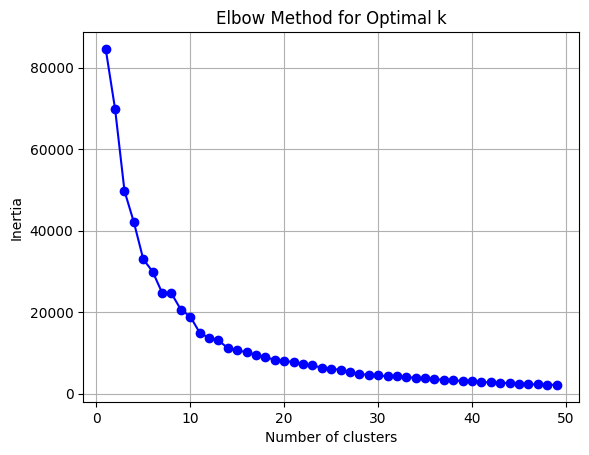

In [104]:
# Elbow plot
plt.plot(K, inertia, 'bo-')
plt.xlabel('Number of clusters')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal k')
plt.grid(True)
plt.show()

In [105]:
# Apply K-means with K=13
kmeans = KMeans(n_clusters=13, random_state=999)
kmeans.fit(X_train.T)

KMeans(n_clusters=13, random_state=999)

In [106]:
# Centroids of the clusters
centroids = kmeans.cluster_centers_

# Extract the numerical values from the X_train DataFrame
df = X_train.T
a = df.values

# Find the features that are closest to the centroids
distances = np.linalg.norm(a - centroids[:, np.newaxis], axis=2)
closest_centroid_indices = np.argmin(distances, axis=1)
closest_feat = df.iloc[closest_centroid_indices]

# Display the selected indicators
closest_feat

,199,200,201,202,203,204,205,206,207,208,...,789,790,791,792,793,794,795,796,797,798
EMA_25_mkt,0.567919,0.565543,0.570500,0.580537,0.591947,0.618464,0.639688,0.663978,0.679843,0.697648,...,1.414684,1.429266,1.447173,1.459617,1.476208,1.495301,1.512521,1.531098,1.546703,1.562339
SMA_100_cma,-0.994213,-0.971929,-0.956337,-0.940718,-0.923960,-0.908092,-0.890146,-0.865448,-0.842186,-0.814803,...,2.699485,2.716834,2.732471,2.746696,2.764183,2.788945,2.813581,2.839145,2.859621,2.882528
EMA_26_rmw,-1.924074,-1.949652,-1.968319,-1.993917,-2.020857,-2.058141,-2.089181,-2.112495,-2.138493,-2.158733,...,-0.309989,-0.304661,-0.289563,-0.283446,-0.282566,-0.283820,-0.280250,-0.276567,-0.271600,-0.271798
EMA_25_smb,-0.411982,-0.348326,-0.297678,-0.245338,-0.198204,-0.169977,-0.151070,-0.139364,-0.114414,-0.080401,...,0.657898,0.644488,0.632355,0.629261,0.621242,0.610267,0.592410,0.564217,0.531935,0.503997
EMA_25_umd,-0.074440,-0.051749,-0.026793,0.001088,0.021370,0.032115,0.038514,0.039203,0.038730,0.026990,...,1.113726,1.099755,1.082849,1.058963,1.048096,1.038866,1.022290,1.007350,0.992235,0.979323
EMA_12_cma,0.343546,0.346253,0.322478,0.304298,0.299241,0.258486,0.210894,0.185952,0.137081,0.135838,...,2.037048,2.017845,2.000805,2.016910,2.076240,2.178361,2.243057,2.298825,2.339921,2.385663
RSI_9_cma,1.123193,0.165240,-0.226871,-0.195331,-0.016462,-0.612524,-0.804021,-0.481338,-0.913511,-0.123504,...,-0.646884,-0.517313,-0.542180,0.487297,1.415441,2.027577,1.361349,1.375155,1.174118,1.354439
EMA_26_hml,-0.661402,-0.668716,-0.671682,-0.676230,-0.680419,-0.683783,-0.683141,-0.688034,-0.686710,-0.680065,...,2.269135,2.282866,2.292373,2.303021,2.308973,2.311521,2.319788,2.327621,2.335577,2.345535
RSI_9_rmw,-1.318809,-1.537358,-0.999391,-1.418261,-1.559550,-1.992794,-1.631758,-1.105015,-1.312634,-0.943711,...,0.658183,0.726436,1.360319,0.511786,0.085500,-0.090388,0.294753,0.325020,0.458046,-0.065593
RSI_9_mkt,-0.461562,-0.011327,0.403526,0.682316,0.788410,1.415922,1.140298,1.312138,0.755868,0.900264,...,1.028409,1.080411,1.332607,0.804338,1.123489,1.330265,1.273090,1.429216,1.183434,1.269768


In [107]:
# Construct the feature matrices for the training and test sets
df = X_train

columns_to_keep = list(df.columns[:6])  # Create a list from the slice
columns_to_keep.extend(df.columns[-2:])
columns_to_keep.extend(['EMA_26_hml', 'EMA_25_smb',
                      'EMA_26_mkt', 'EMA_25_umd', 'RSI_9_rmw',
                      'EMA_25_cma', 'RSI_9_hml', 'RSI_9_umd',
                      'RSI_9_mkt', 'RSI_9_smb', 'RSI_9_cma',
                      'SMA_200_smb'])

X_train = X_train[columns_to_keep]
X_test = X_test[columns_to_keep]

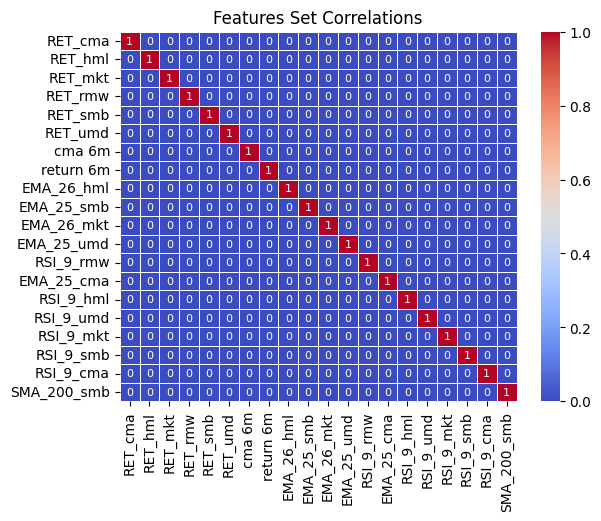

In [108]:
import seaborn as sns
df = X_train

# Show pairs with very high correlation
sns.heatmap(df.corr()>0.8,
annot=True,
annot_kws={"size": 8},
linewidth=.5,
cmap="coolwarm",
cbar=True);

plt.title('Features Set Correlations');

In [109]:
# EDA on the final input matrix
X_train.describe().T

,count,mean,std,min,25%,50%,75%,max
RET_cma,600.0,-1.184238e-17,1.000834,-3.830998,-0.609815,0.017945,0.616419,3.416566
RET_hml,600.0,1.184238e-17,1.000834,-3.744837,-0.588540,-0.070575,0.580431,4.334948
RET_mkt,600.0,1.776357e-17,1.000834,-5.547969,-0.519378,0.019665,0.570375,5.369493
RET_rmw,600.0,-5.921189e-18,1.000834,-3.473065,-0.599465,0.015365,0.679707,3.996950
RET_smb,600.0,4.440892e-18,1.000834,-4.395884,-0.544593,0.063518,0.621712,4.046302
RET_umd,600.0,-1.184238e-17,1.000834,-3.836412,-0.596548,-0.019077,0.629593,4.350155
cma 6m,600.0,0.000000e+00,1.000834,-2.540868,-0.641517,0.102235,0.720036,2.105398
return 6m,600.0,-4.263256e-16,1.000834,-2.563620,-0.573980,0.337349,0.736092,1.702239
EMA_26_hml,600.0,-3.315866e-16,1.000834,-1.399319,-0.766978,-0.548790,0.772060,2.345535
EMA_25_smb,600.0,-1.421085e-16,1.000834,-1.892147,-1.078068,0.294441,0.852150,1.785322


## Models

In [110]:
# Create path to save the results
from pathlib import Path

results_path = Path('results', 'lstm_time_series')
if not results_path.exists():
    results_path.mkdir(parents=True)

In [111]:
# Check class frequency
c = np.bincount(y_train)
c

array([141, 459], dtype=int64)

In [112]:
import matplotlib.pyplot as plt
import seaborn as sns  # Import seaborn


In [128]:
import src
from src.config import *
from tensorflow.keras.preprocessing.sequence import TimeseriesGenerator

# Calculate class weights
class_weight = cwts(y_train)

# Check the class weights
class_weight[0] * c[0], class_weight[1] * c[1]

OSError: 'seaborn' is not a valid package style, path of style file, URL of style file, or library style name (library styles are listed in `style.available`)

In [134]:
import matplotlib.pyplot as plt
plt.style.use('ggplot')  # or any other available style



In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.losses import BinaryCrossentropy
from tensorflow.keras.metrics import BinaryAccuracy, AUC
from tensorflow.keras.preprocessing.sequence import TimeseriesGenerator

In [121]:
# Sequence length
seqlen = 10
# Number of features
numfeat = X_train.shape[1]

# Generate train and test sequence input
g = TimeseriesGenerator(X_train, y_train, length=seqlen)
g_ = TimeseriesGenerator(X_test, y_test, length=seqlen)

ValueError: `start_index+length=10 > end_index=0` is disallowed, as no part of the sequence would be left to be used as current step.

In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.optimizers.legacy import Adam
from tensorflow.keras.losses import BinaryCrossentropy
from tensorflow.keras.metrics import BinaryAccuracy, AUC

# Define the function to create the model
def create_model(hu=20, lookback=10, features=1):
    
    tf.keras.backend.clear_session()   

    # Instantiate the model
    model = Sequential()
    
    model.add(LSTM(units=hu, input_shape=(lookback, features), activation='relu', return_sequences=False, name='LSTM1'))
    model.add(Dropout(0.4, name='Dropout1'))
    
    model.add(Dense(units=1, activation='sigmoid', name='Output'))             
    
    # Specify optimizer
    opt = Adam(learning_rate=0.001, epsilon=1e-08, decay=0.0)       
    
    # Model compilation
    model.compile(optimizer=opt, 
                  loss=BinaryCrossentropy(), 
                  metrics=[BinaryAccuracy(name='accuracy', threshold=0.5), AUC()])

    return model

# Example data generation (for demonstration purposes)
seqlen = 10  # Length of sequences (lookback)
numfeat = 1  # Number of features

# Generate sample data
def generate_sequence(length, n_features):
    return np.random.rand(length, n_features)

# Generate sample training data
n_samples = 100
X = np.array([generate_sequence(seqlen, numfeat) for _ in range(n_samples)])
y = np.random.randint(2, size=n_samples)  # Binary target for demonstration

# Create the model
model = create_model(hu=10, lookback=seqlen, features=numfeat)

# Display the model summary
model.summary()


Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 LSTM1 (LSTM)                (None, 10)                480       
                                                                 
 Dropout1 (Dropout)          (None, 10)                0         
                                                                 
 Output (Dense)              (None, 1)                 11        
                                                                 
Total params: 491 (1.92 KB)
Trainable params: 491 (1.92 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [ ]:
# Model fitting
model.fit(g,
          epochs=300, 
          verbose=1, 
          callbacks=my_callbacks, 
          shuffle=False,
          class_weight=class_weight)

NameError: name 'my_callbacks' is not defined